In [1]:
import os
import pandas as pd
import numpy as np
import scipy
import math
import plotnine
import matplotlib.pyplot as plt
import warnings
from scipy.integrate import solve_ivp
from datetime import datetime
from datetime import timedelta
from scipy.interpolate import interp1d

In [2]:
all_scalings= pd.read_csv("../data/scaling_relationships_calc.csv")

half_sats_p = pd.read_csv("../../2026_08_29_complete_workflow/output_estimation_logN_linP_20260918/half_sats/phosphorus_half_sats.csv")
half_sats_p = half_sats_p.loc[half_sats_p.exponential_p_val < 0.11,:]
half_sats_p=half_sats_p.loc[half_sats_p.exponential_slope<=0,:]
half_sats_n = pd.read_csv("../../2026_08_29_complete_workflow/output_estimation_logN_linP_20260918/half_sats/nitrogen_half_sats.csv")
half_sats_n = half_sats_n.loc[half_sats_n.exponential_p_val < 0.11,:]
half_sats_n=half_sats_n.loc[half_sats_n.exponential_slope<=0,:]

def get_half_sat(Taxon,nutrient="P"):
    half_sats=half_sats_n
    if nutrient=="P":
        half_sats=half_sats_p.copy(deep=True)
        half_sats.estimated_parameter=half_sats.estimated_parameter
    
    if (Taxon not in list(half_sats.Taxon)):
        return all_scalings.loc[all_scalings.taxon==Taxon,"half_sat_"+nutrient.lower()].iloc[0]
    if (half_sats.loc[half_sats.Taxon==Taxon,"exponential_slope"].iloc[0]>0):
        return all_scalings.loc[all_scalings.taxon==Taxon,"half_sat_"+nutrient.lower()].iloc[0]
            
    return float(half_sats.loc[half_sats.Taxon==Taxon,
                               "estimated_parameter"])

temp_relation=pd.read_csv("../../2026_08_29_complete_workflow/output_estimation_logN_linP_20260918/temp_relation/temperature_mean_std.csv")
def get_temp_params(Taxon,param="mean"):
    if len(temp_relation.loc[temp_relation.Order==Taxon,"mean_temp"])==0 & (param=="mean"):
        return 8
    if len(temp_relation.loc[temp_relation.Order==Taxon,"mean_temp"])==0 & (param=="std"):
        return 5
    if param=="mean":
        if len(temp_relation.loc[temp_relation.Order==Taxon,"mean_temp"])==0 | \
            (temp_relation.loc[temp_relation.Order==Taxon,"mean_temp"].iloc[0]\
           !=temp_relation.loc[temp_relation.Order==Taxon,"mean_temp"].iloc[0]):
            return 8
        return float(temp_relation.loc[temp_relation.Order==Taxon,"mean_temp"])
    if param=="std":
        if len(temp_relation.loc[temp_relation.Order==Taxon,"std_temp"])==0 | \
           (temp_relation.loc[temp_relation.Order==Taxon,"std_temp"].iloc[0]\
           !=temp_relation.loc[temp_relation.Order==Taxon,"std_temp"].iloc[0]):
            return 5
        return float(temp_relation.loc[temp_relation.Order==Taxon,"std_temp"])

In [3]:
list(set(half_sats_p.Taxon).intersection(set(half_sats_n.Taxon)))

['Chaetocerotophycidae',
 'Leptocylindrales',
 'Gymnodiniales',
 'Thalassiosirales']

In [4]:
list(set(half_sats_p.Taxon).intersection(set(half_sats_n.Taxon)))

['Chaetocerotophycidae',
 'Leptocylindrales',
 'Gymnodiniales',
 'Thalassiosirales']

In [5]:
organisms_for_model = list(set(half_sats_p.Taxon).union(set(half_sats_n.Taxon))) + \
    ["Coscinodiscales"]

In [6]:
def get_max_gr(taxon):
    return float(all_scalings.loc[all_scalings.taxon==taxon,"max_growth_rate"])

### parameters from the 2026 exercise
consistent_k_light = 500
consistent_T_opt = 8
consistent_std_T = 5
consistent_max_gr = 1
consistent_half_sat_silicon = 1
consistent_half_sat_metab = 0.5
consistent_half_sat_nitr = 1
consistent_half_sat_phos = 0.1

params_frame={}
for organism in organisms_for_model:
    half_sat_nitr = get_half_sat(organism,"N")
    half_sat_phos = get_half_sat(organism,"P")
    #if half_sat_nitr == "not_found":
    #    half_sat_nitr = consistent_half_sat_nitr
    #if half_sat_phos == "not_found":
    #    half_sat_phos = consistent_half_sat_phos
    max_gr=consistent_max_gr # change to maximum weighted biomass
    
    current_org_dict={"max_gr":get_max_gr(organism),
                      "half_sat_nitr":half_sat_nitr,
                      "half_sat_phos":half_sat_phos,
                      "T_opt":get_temp_params(organism,"mean"),
                      "std_T":get_temp_params(organism,"std")}
    params_frame[organism]=current_org_dict

/tmp/ipykernel_3405172/3094506930.py:21: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
/tmp/ipykernel_3405172/640212947.py:2: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
/tmp/ipykernel_3405172/3094506930.py:35: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
/tmp/ipykernel_3405172/3094506930.py:41: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead


In [20]:
params_frame

{'Lithodesmiales': {'max_gr': 0.8237121987999367,
  'half_sat_nitr': 4.26983203357398,
  'half_sat_phos': np.float64(0.5191210977287466),
  'T_opt': 4.0226,
  'std_T': 0.762648889070193},
 'Hemiaulales': {'max_gr': 0.8237121987999367,
  'half_sat_nitr': np.float64(8.48563332825836),
  'half_sat_phos': 0.0278045731435004,
  'T_opt': 12.974568,
  'std_T': 7.66355875339388},
 'Cryptomonadales': {'max_gr': 9.004943501560748,
  'half_sat_nitr': 0.0677045332241588,
  'half_sat_phos': np.float64(0.1957658326127179),
  'T_opt': 7.614828,
  'std_T': 3.33708366572571},
 'Mamiellales': {'max_gr': 1.3016103470475997,
  'half_sat_nitr': np.float64(0.4956241706172001),
  'half_sat_phos': 0.0083447195557889,
  'T_opt': 9.013844,
  'std_T': 5.62011614882468},
 'Chaetocerotophycidae': {'max_gr': 1.014108671756599,
  'half_sat_nitr': 0.11757363763927,
  'half_sat_phos': 0.488715065988506,
  'T_opt': 10.629032,
  'std_T': 8.28358068848973},
 'Prymnesiales': {'max_gr': 3.5784844829840607,
  'half_sat_nitr

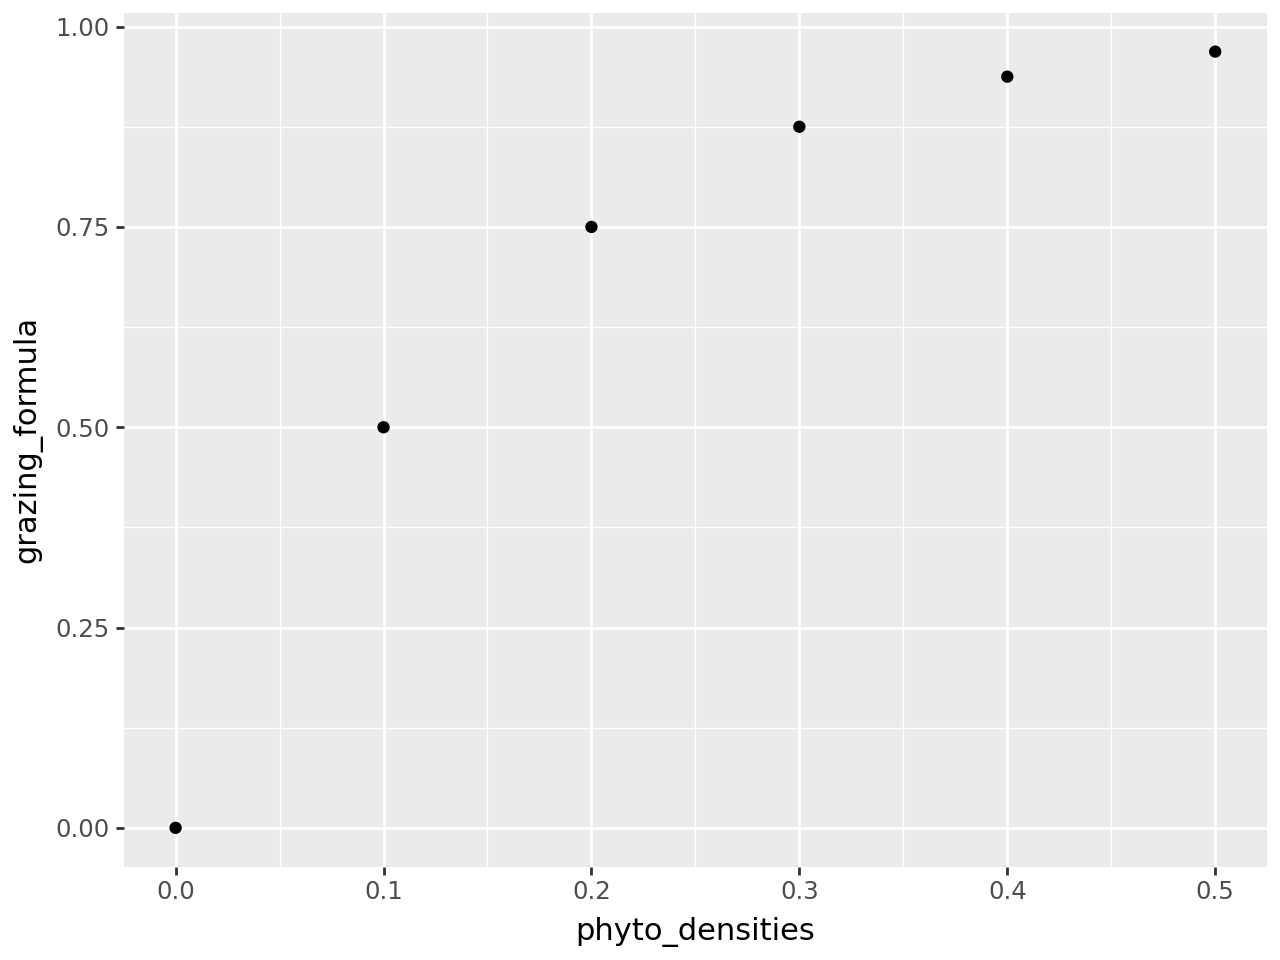

In [21]:
phyto_densities=[0,0.1,0.2,0.3,0.4,0.5]
half_sat_graz = 0.1
saturation_rate = 0.693/half_sat_graz
densities=pd.DataFrame({"grazing_formula":[(1-np.exp(-saturation_rate*phyto_density)) for phyto_density in phyto_densities],
                        "phyto_densities":phyto_densities})
(plotnine.ggplot(densities)+
     plotnine.geom_point(plotnine.aes(x="phyto_densities",y="grazing_formula")))

In [13]:
def identify_limiting_nutrient(mm_n,mm_p,mm_s,mm_m):
    return min(mm_n,mm_p,mm_s,mm_m)

## notes - now doing this per day - but continue to include light variability over the year
## by averaging the total light over the course of the day (lower average during darker months)
def calculate_growth_rate(k_light, mu_max, T_opt, std_T, 
                          limiting_resource, Temp, Light, mortality_rate):
    light_sensitivity = 1 #Light / (k_light + Light)
    temp_sensitivity = np.exp(-((Temp - T_opt)/(std_T*2))**2)
    GR = mu_max * limiting_resource * light_sensitivity * temp_sensitivity
    return GR

def calculate_limiting_original(half_sat, Resource, maxResource):
    if Resource < 0:
        Resource = 0
    U = Resource / (half_sat + Resource)
    return U

def calculate_limiting(half_sat, Resource, maxResource):
    
    if Resource < 0:
        Resource = 0
    beta = 0.5
    inhibition_constant = half_sat * 2
    U = Resource / (Resource + half_sat)
    #U = (Resource - half_sat / 2)/ (half_sat + Resource + (Resource**2) / inhibition_constant)
   # U = (Resource)/ (half_sat + Resource + (Resource**2) / inhibition_constant)

    if (U < 0)|(Resource<0.001):
        U = 0
    return U

def calculate_all_limiting(organism_list, parameters, resource_code,
                         Resource, maxResource, temp_curr, light_curr):
    limiting_list=[]
    for organism in organism_list:
        if resource_code == "Nitr":
            half_sat_nitr=parameters[organism]["half_sat_nitr"]
            limiting_list.append(calculate_limiting(half_sat_nitr, 
                                                Resource, 
                                                maxResource))
        elif resource_code == "Phos":
            half_sat_phos=parameters[organism]["half_sat_phos"]
            limiting_list.append(calculate_limiting(half_sat_phos, 
                                                Resource, 
                                                maxResource))
   
    return limiting_list

def holling_type_three(half_sat_graz, phyto_density, refuge_phyto, graz_max):
    return graz_max * (phyto_density**2) / \
        (half_sat_graz**2+(phyto_density**2))
  
def ivlev_grazing(half_sat_graz, saturation_rate, 
                  grazing_preference,
                  phyto_density, graz_max):
    return graz_max  * grazing_preference * (1-np.exp(-saturation_rate*phyto_density))

# P = current phyto conc
# graz_max = max grazing 
# saturation_rate = Ivlev grazing saturation constant
# alpha = switching exponent
def kill_the_winner_ivlev(P, graz_max, saturation_rate, alpha=2.0):
    
    P = np.array(P, dtype=float)
    
    # Avoid division by zero if all phytoplankton are completely depleted
    if np.sum(P) == 0:
        return np.zeros_like(P)
    
    # 1. Calculate density dependence of predation
    numerator = (P ** alpha)
    p_dynamic = numerator / np.sum(numerator)
    
    # 2. Calculate total effective food that zoops have access to
    F = np.sum(p_dynamic * P)
    
    # 3. Calculate multi-prey Ivlev ingestion rate for each species
    g_i = graz_max * p_dynamic * (1.0 - np.exp(-saturation_rate * F))
    
    return g_i

def transporter_model_all_resource(time, state, organism_list, parameters, time_vect, sub_frame_temp):
    curr_index = int(time)
    
    if curr_index % 15 == 1: #nitr.DateTime[curr_index].day==1:
        state[-2] = float(nitr_with_index.loc[nitr_with_index["index"]==curr_index-1,
                                              "nitrogen"].iloc[0])
        state[-1] = float(phos_with_index.loc[phos_with_index["index"]==curr_index-1,
                                              "phosphorus"].iloc[0])
        
    ## read in environmental variables
    light_curr = light[curr_index] # light
    temp_curr = sub_frame_temp.\
        loc[sub_frame_temp["index"]==curr_index,\
            "temperature_daily"].iloc[0] # temperature
    
    nitr_curr=state[-2]
    phos_curr=state[-1]
    max_nitr = np.max(nitr_with_index.nitrogen)
    max_phos = np.max(phos_with_index.phosphorus)
    
    chl_curr = 10 # ug/L
    mortality_rate = 0.2
    zoop_mortality = 0.01
    graz_max = 0.5
    half_sat_graz = 0.5
    saturation_rate = 0.693/half_sat_graz
    refuge_phyto = 0.25 # population at which grazing is alleviated (they're hiding)
    
    alpha = 2 # scaling to control "kill the winner" dynamics
    
    half_sat_Phy = 0.5
    assimilation = 0.4

    limiting_vect_Nitr = calculate_all_limiting(organism_list,
                                                parameters, resource_code = "Nitr",
                             Resource=nitr_curr, maxResource = max_nitr,
                             temp_curr=temp_curr, light_curr=light_curr)
    
    limiting_vect_Phos = calculate_all_limiting(organism_list,
                                                parameters, resource_code = "Phos",
                             Resource=phos_curr, maxResource = max_phos,
                             temp_curr=temp_curr, light_curr=light_curr)

    n_limiting.append([time,limiting_vect_Nitr])
    p_limiting.append([time,limiting_vect_Phos])
    
    growth_rates=[]
    grazing_amount=[]
    growth_multipliers=[]
    increase_phytos=[]
    d_phytos=[]
    overall_phyto_density = sum(state[0:-3])
    grazing_rates = kill_the_winner_ivlev(state[0:-3],graz_max,saturation_rate,alpha=alpha)
    for curr_org,ind_org in zip(organism_list,range(len(organism_list))):
        pref_denom = [state_curr**alpha for state_curr in state[0:-3]]
        grazing_preferences = state[ind_org]**alpha / sum(pref_denom)
        mu_max = parameters[curr_org]["max_gr"]
        
        limiting_resource = min(limiting_vect_Nitr[ind_org],
                                limiting_vect_Phos[ind_org])
            
        if limiting_vect_Nitr[ind_org] == limiting_resource:
            growth_multiplier = limiting_vect_Nitr[ind_org] 
        else:
            growth_multiplier = limiting_vect_Phos[ind_org]
        
        growth_multipliers.append(growth_multiplier)
        limiting_resources.append([time,limiting_resource])
        k_light = consistent_k_light
        T_opt = parameters[curr_org]["T_opt"]
        std_T = parameters[curr_org]["std_T"]
        gr_curr=calculate_growth_rate(k_light, mu_max, T_opt, 
                                      std_T, limiting_resource, temp_curr,
                                      light_curr, mortality_rate)
        
        growth_rates.append(gr_curr)
        increase_phytos.append(gr_curr*(state[ind_org]+0.01))
        d_phytos.append(gr_curr*(state[ind_org]+0.01)-\
                        grazing_rates[ind_org]*state[-3]-\
                        mortality_rate*state[ind_org]**2)
        grazing_amount.append(grazing_rates[ind_org]*state[-3])

        
    
    d_zoop = assimilation * sum(grazing_amount)-\
             zoop_mortality * (state[-3]+0.01)
    d_nitr = ((mortality_rate * sum(state[0:-3]**2) +
              (1-assimilation) * sum(grazing_amount) + \
              zoop_mortality * state[-3] - \
              sum(increase_phytos)))*16/17
    d_phos = ((mortality_rate * sum(state[0:-3]**2) +
              (1-assimilation) * sum(grazing_amount) + \
              zoop_mortality * state[-3] - \
              sum(increase_phytos)))*1/17
    
             #sum(grazing_rates) * (state[-3]+0.01) - \
               #sum(grazing_rates) * state[-3] + 
    return d_phytos + [d_zoop,d_nitr,d_phos]

### FUNCTION FOR INFILLING DATA ON DAYS TO GET NEAREST MONTH ###

def diff_month(d1, d2):
    return (d1.year - d2.year) * 12 + d1.month - d2.month

def infill_data(ptown_data_input,variable_in):
    for curr in range(0,len(ptown_data_input.index)):
        if ptown_data_input[variable_in][curr]!=ptown_data_input[variable_in][curr]: ## if data missing
            variable_differences = pd.DataFrame({"var_diff": ptown_data_input["DateMonthYr"]-ptown_data_input.DateTime[curr],
                                                 "date_month_yr": ptown_data_input.DateMonthYr,
                                                 "month": ptown_data_input.Month,
                                                 "variable": ptown_data_input[variable_in],
                                                 "index": list(range(0,len(ptown_data_input.index)))})
            variable_differences=variable_differences.drop_duplicates(subset=["date_month_yr"])
            variable_differences = variable_differences.loc[variable_differences["variable"]==variable_differences["variable"],:]
            variable_differences_1=variable_differences.copy(deep=True)
            variable_differences_1["abs_diff"] = np.abs(variable_differences_1.var_diff)
            variable_differences_1 = variable_differences_1.loc[[curr>timedelta(0) for curr in variable_differences_1.var_diff],:]
            variable_differences_1 = variable_differences_1.sort_values("abs_diff",ascending=True).head(n=1) ## get the closest values
           
            variable_differences_2=variable_differences.copy(deep=True)
            variable_differences_2["abs_diff"] = np.abs(variable_differences_2.var_diff)
            variable_differences_2 = variable_differences_2.loc[[curr<timedelta(0) for curr in variable_differences_2.var_diff],:]
            variable_differences_2 = variable_differences_2.sort_values("abs_diff",ascending=True).head(n=1)
            variable_differences_2 = variable_differences_2.sort_values("date_month_yr")
            
            variable_differences_1 = pd.concat([variable_differences_1,variable_differences_2]).reset_index()

            value_out = variable_differences_1["variable"][0] +\
                (variable_differences_1["variable"][1] - variable_differences_1["variable"][0]) / \
                diff_month(variable_differences_1.date_month_yr[0],
                           variable_differences_1.date_month_yr[1])
            
            if (variable_in=="temperature")&(ptown_data_input.Month[curr]):
                value_out = variable_differences_1["variable"][0] -\
                (variable_differences_1["variable"][1] - variable_differences_1["variable"][0]) / \
                diff_month(variable_differences_1.date_month_yr[0],
                           variable_differences_1.date_month_yr[1])

            ptown_data_input[variable_in][curr] = value_out
    return ptown_data_input

In [8]:
irradiance = pd.read_csv("../data/irradiance.csv")
time_vect = pd.date_range(datetime.strptime('2000-02-01 00:00',"%Y-%m-%d %H:%M"),
                          datetime.strptime("2023-10-30 00:00","%Y-%m-%d %H:%M"), freq='h')
month_vect = [dt.month for dt in time_vect]
hour_vect = [dt.hour for dt in time_vect]
set_zeros_1 = [max(0,hr_curr-6-round(abs(mnth_curr-6)/3,0)) for hr_curr,mnth_curr in zip(hour_vect,month_vect)]
set_zeros_2 = [max(0,22-abs(mnth_curr-6)-hr_curr) for hr_curr,mnth_curr in zip(hour_vect,month_vect)]
light = [2500  / np.sqrt(max(1,abs(6-mnth_curr)))  * np.sin(np.pi/2 * \
                                                            min(set_zeros_1_c,set_zeros_2_c)/max(set_zeros_1_c,set_zeros_2_c))\
         for mnth_curr,set_zeros_1_c,set_zeros_2_c in zip(month_vect,set_zeros_1,set_zeros_2)] 
## light is normalized to a daily cycle - more light happens in June & day is longer.
## in June, sunlight is from ~6am to 9pm, in December it's from ~9am to 4pm. 

light_fr=pd.DataFrame({"light":light,"DateTime":time_vect})
light_fr["Year"] = [dt.year for dt in light_fr.DateTime]
light_fr["Month"] = [dt.month for dt in light_fr.DateTime]
light_fr["Day"] = [dt.day for dt in light_fr.DateTime]
light_fr["Hour"] = [dt.hour for dt in light_fr.DateTime]
light_fr = light_fr.groupby(["Year","Month","Day"]).light.mean().reset_index()

light = list(light_fr.light)

### TEMPERATURE CALCULATION ###
time_vect = pd.date_range(datetime.strptime('2000-02-01 00:00',"%Y-%m-%d %H:%M"),
                          datetime.strptime("2023-11-01 00:00","%Y-%m-%d %H:%M"), freq='M')

temps_ptown = pd.read_csv("../data/temperatures.csv")

temps_ptown["Date"]=[datetime.strptime(date_string, "%Y-%m-%d") for date_string in temps_ptown.Date]
temps_ptown = temps_ptown.groupby(["Date","STAT_ID"]).FFU_RESULT.mean().reset_index().\
    rename({"FFU_RESULT":"temperature"},axis="columns")

temps_ptown["DateMonthYr"] = [dt.replace(day=1) for dt in temps_ptown["Date"]]
temps_ptown = temps_ptown.sort_values("DateMonthYr")
temps_ptown["Month"] = [dt.month for dt in temps_ptown["Date"]]
temps_ptown["Year"] = [dt.year for dt in temps_ptown["Date"]]

to_infill = pd.DataFrame({"DateTime":time_vect})
to_infill["Year"] = [dt.year for dt in to_infill.DateTime]
to_infill["Month"] = [dt.month for dt in to_infill.DateTime]
to_infill["Hour"] = [dt.hour for dt in to_infill.DateTime]
to_infill = to_infill.merge(temps_ptown,on=["Month","Year"],how="left")
temp_1 = infill_data(to_infill,"temperature")

time_vect = pd.date_range(datetime.strptime('2000-02-01 00:00',"%Y-%m-%d %H:%M"),
                          datetime.strptime("2023-10-30 00:00","%Y-%m-%d %H:%M"), freq='h')

time_frame_2 = pd.DataFrame({"DateTime":time_vect})
time_frame_2["Year"] = [dt.year for dt in time_frame_2.DateTime]
time_frame_2["Month"] = [dt.month for dt in time_frame_2.DateTime]
time_frame_2["Day"] = [dt.day for dt in time_frame_2.DateTime]
time_frame_2["Hour"] = [dt.hour for dt in time_frame_2.DateTime]
daily_temp_fr_2 = time_frame_2.merge(temp_1.loc[:,["Month","Year","temperature"]].drop_duplicates(subset=["Month","Year"]),
                     on=["Month","Year"],how="left")

daily_temp_fr_2["temperature_hourly"]=[temperature + np.sin(2*np.pi*(Hour-6)/24)/2 for temperature,Hour in\
                                       zip(daily_temp_fr_2.temperature,daily_temp_fr_2.Hour)]

daily_temp_fr_2 = daily_temp_fr_2.groupby(["Year","Month","Day"]).temperature_hourly.mean().reset_index()
#########

/tmp/ipykernel_3405172/1481900681.py:24: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
/tmp/ipykernel_3405172/1111793996.py:221: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/tmp/ipykernel_

In [9]:
nerrs_data = pd.read_csv("../data/nerrs_data_cleaned.csv")
nerrs_data["DateTime"] = [datetime.strptime(date_curr,"%Y-%m-%d") for \
                          date_curr in nerrs_data["DateTime"]]

In [16]:
nerrs_data

,Unnamed: 0,DateTime,NERR.Site.ID,nitrogen,phosphorus
0,1,2002-01-06,niw,6.620781,0.875963
1,2,2002-01-07,del,86.662206,1.090975
2,3,2002-01-07,niw,7.739472,0.670649
3,4,2002-01-08,ace,4.473335,1.260667
4,5,2002-01-09,ace,3.150131,0.991282
...,...,...,...,...,...
10803,10804,2024-12-18,gnd,1.498929,0.258314
10804,10805,2024-12-18,grb,9.992862,0.408998
10805,10806,2024-12-18,hud,36.973590,0.678076
10806,10807,2024-12-19,hud,39.186296,0.758799


In [10]:
nerrs_data_temp = pd.read_csv("../data/nerrs_data_cleaned_temp.csv")
nerrs_data_temp["DateTime"] = [datetime.strptime(date_curr,"%Y-%m-%d") for \
                          date_curr in nerrs_data_temp["DateTime"]]

In [14]:
combined_sol=pd.DataFrame()
for stat_id in list(set(nerrs_data["NERR.Site.ID"])):
    sub_frame=nerrs_data.loc[nerrs_data["NERR.Site.ID"]==stat_id,:]
    sub_frame_temp_=nerrs_data_temp.loc[nerrs_data_temp["NERR.Site.ID"]==stat_id,:]
    if len(sub_frame_temp_.index)==0:
        continue
    time_vect = pd.date_range(np.min(sub_frame.DateTime),
                              np.max(sub_frame.DateTime), freq='D')

    f_nearest = interp1d(sub_frame.DateTime.astype('int64'), 
                         sub_frame.nitrogen, 
                         kind='nearest', fill_value="extrapolate")
    convert_frame=pd.DataFrame({"DateTime":time_vect})
    convert_frame["nitrogen"] = f_nearest(time_vect.astype('int64'))
    f_nearest = interp1d(sub_frame.DateTime.astype('int64'), 
                         sub_frame.phosphorus, 
                         kind='nearest', fill_value="extrapolate")
    convert_frame["phosphorus"] = f_nearest(time_vect.astype('int64'))
    
    sub_frame_temp=pd.DataFrame({"DateTime":time_vect})
    f_nearest = interp1d(sub_frame_temp_.DateTime.astype('int64'), 
                         sub_frame_temp_.Temp, 
                         kind='nearest', fill_value="extrapolate")
    sub_frame_temp["temperature_daily"] = f_nearest(time_vect.astype('int64'))
    
    dates_with_index = pd.DataFrame(time_vect,columns=["DateTime"]).reset_index()
    nitr_with_index = convert_frame.merge(dates_with_index,on="DateTime",how="inner")
    phos_with_index = convert_frame.merge(dates_with_index,on="DateTime",how="inner")
    sub_frame_temp = sub_frame_temp.merge(dates_with_index,on="DateTime",how="inner")

    n_limiting = []  # Global variable
    p_limiting = []  # Global variable
    si_limiting = []  # Global variable
    d_Hs = []
    limiting_resources = []  # Global variable
    nitrogen_start=nitr_with_index.nitrogen[0]
    phos_start = phos_with_index.phosphorus[0]

    state={}
    for org in organisms_for_model:
        state[org]=0.5
    state["zoop"]=0.5
    state["nitrogen"]=nitrogen_start
    state["phosphorus"]=phos_start

    sol = solve_ivp(transporter_model_all_resource, t_span=[0,len(time_vect)-1],
                    t_eval=list(range(0,len(time_vect)-1,1)),
                    y0=list(state.values()),args=[organisms_for_model,params_frame,time_vect,sub_frame_temp])
    phyto_frame=pd.DataFrame()
    for organism,organism_ind in zip(organisms_for_model,range(len(organisms_for_model))):
        phyto_frame[organism] = sol.y[organism_ind,:]
    phyto_frame["index"]=sol.t
    phyto_frame["zoop"] = list(sol.y[sol.y.shape[0]-3,:])
    phyto_frame["nitrogen"] = list(sol.y[sol.y.shape[0]-2,:]) #n_values
    phyto_frame["phosphorus"] = list(sol.y[sol.y.shape[0]-1,:]) #p_values
    all_sol = phyto_frame.merge(dates_with_index,on="index").melt(id_vars=["DateTime","index"],
                     var_name="taxon",value_name="abund")
    
    all_sol["Site"] = stat_id
    combined_sol = pd.concat([combined_sol,all_sol],axis=0)
    

/tmp/ipykernel_3405172/3543802672.py:79: RuntimeWarning: overflow encountered in exp
/tmp/ipykernel_3405172/3543802672.py:73: RuntimeWarning: invalid value encountered in divide
/tmp/ipykernel_3405172/3543802672.py:138: RuntimeWarning: invalid value encountered in scalar divide
/tmp/ipykernel_3405172/3543802672.py:159: RuntimeWarning: invalid value encountered in scalar multiply
/tmp/ipykernel_3405172/3543802672.py:160: RuntimeWarning: invalid value encountered in scalar multiply
/tmp/ipykernel_3405172/3543802672.py:25: RuntimeWarning: invalid value encountered in scalar divide
/tmp/ipykernel_3405172/3543802672.py:72: RuntimeWarning: overflow encountered in square
/tmp/ipykernel_3405172/3543802672.py:137: RuntimeWarning: overflow encountered in scalar power
/tmp/ipykernel_3405172/3543802672.py:138: RuntimeWarning: overflow encountered in scalar power
/tmp/ipykernel_3405172/3543802672.py:162: RuntimeWarning: overflow encountered in scalar power
/tmp/ipykernel_3405172/3543802672.py:169: 

In [15]:
combined_sol.to_csv("../output/metaT_informed_NERRS_20260926_2.csv")

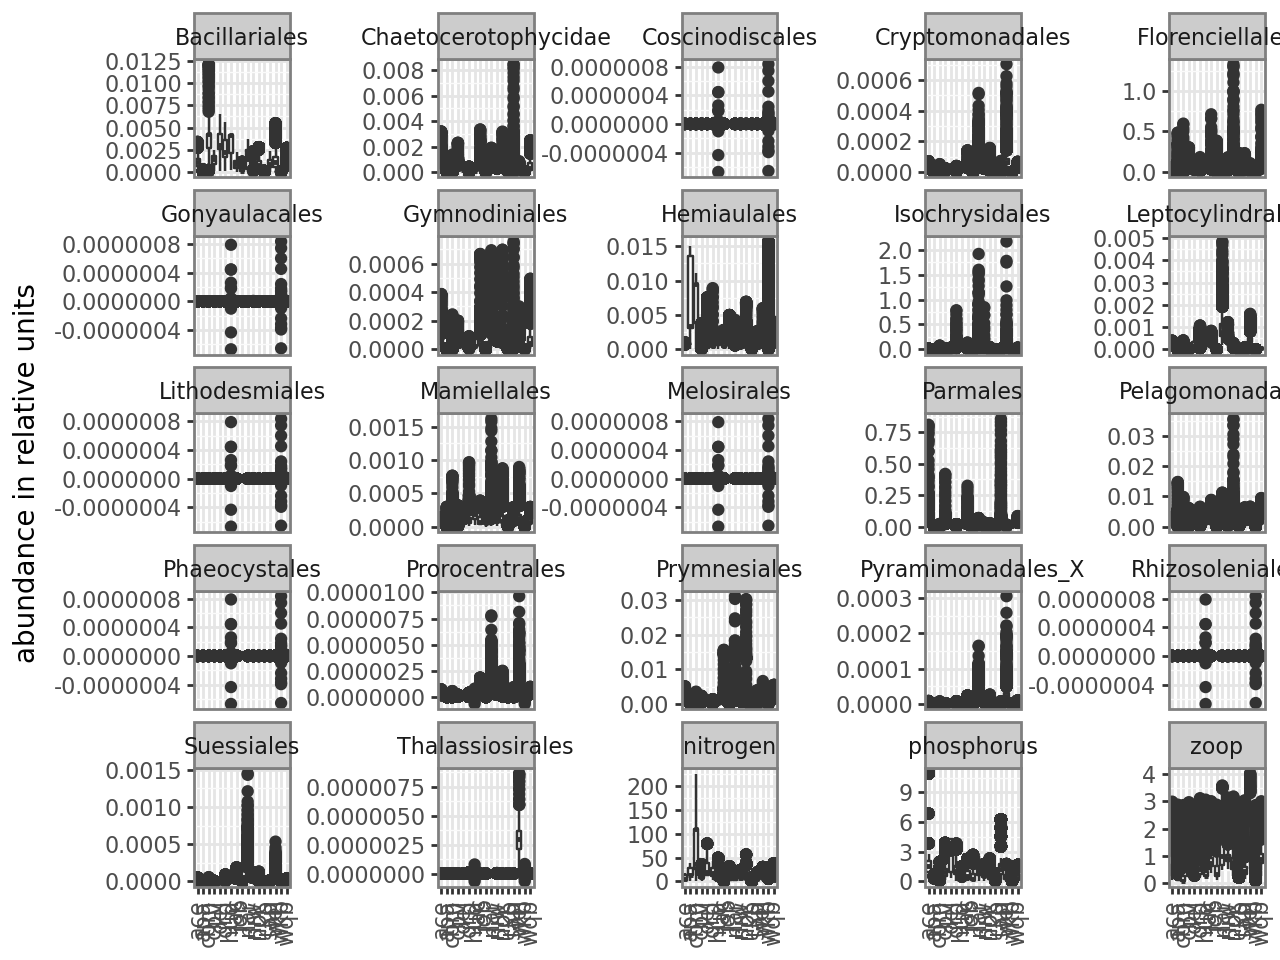

In [19]:
## plot entire timeseries
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42

zoom_in=(plotnine.ggplot(combined_sol.loc[combined_sol["index"]>50,:]) + 
    plotnine.geom_boxplot(plotnine.aes(x="Site",y="abund"),size=0.5)+ 
    #plotnine.facet_wrap("taxon",scales="free_y",ncol=1)+
    plotnine.theme_bw(base_size=10)+plotnine.ylab("abundance in relative units") + 
    plotnine.xlab("") +
    plotnine.theme(axis_text_x=plotnine.element_text(rotation=90, hjust=0.5)) +
    plotnine.facet_wrap("taxon",scales="free_y"))

zoom_in

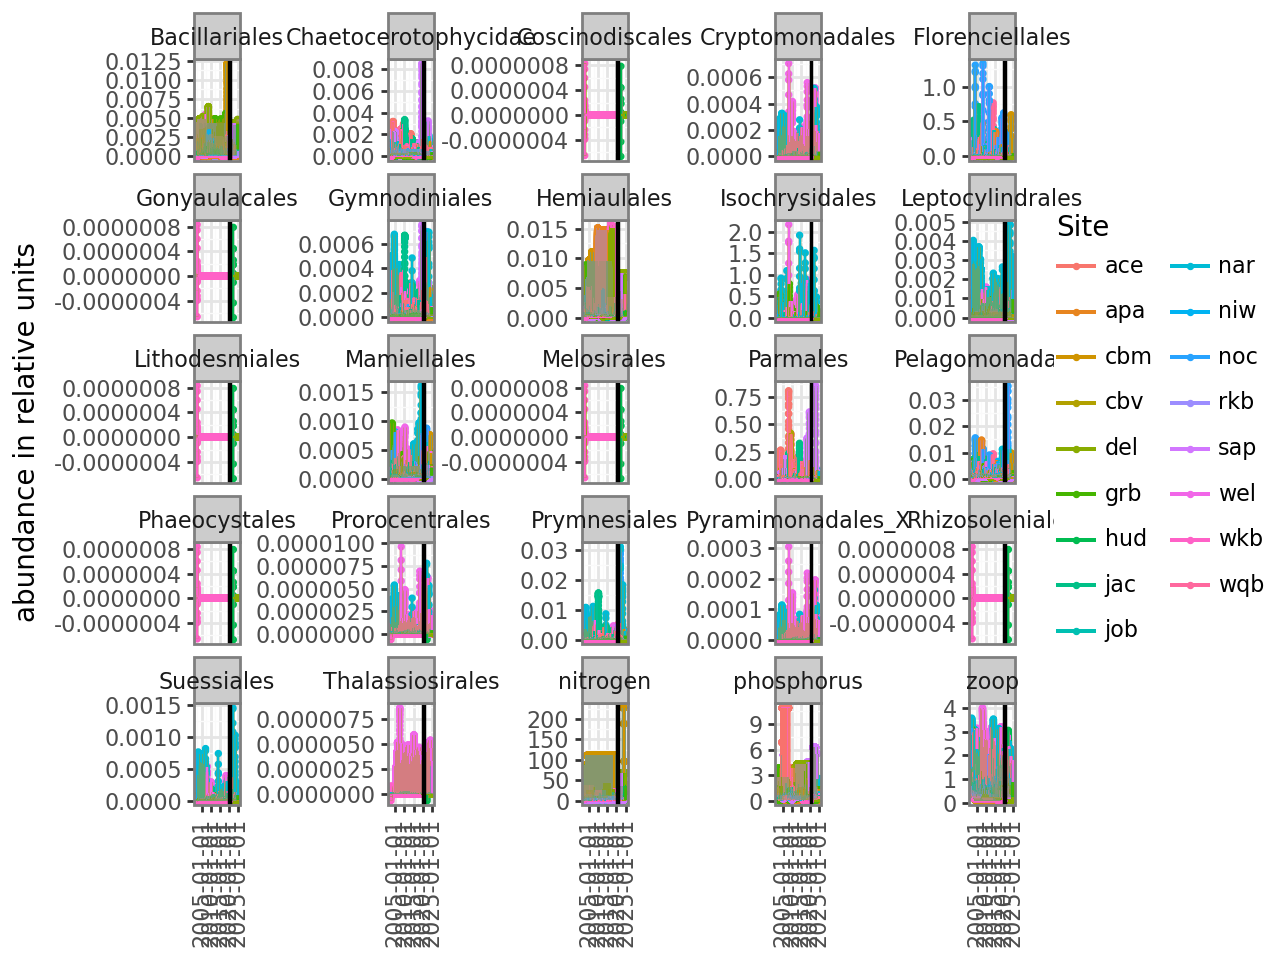

In [18]:
## plot entire timeseries
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42

zoom_in=(plotnine.ggplot(combined_sol.loc[combined_sol["index"]>50,:]) + 
    plotnine.geom_point(plotnine.aes(x="DateTime",y="abund",color="Site"),size=0.5)+ 
    plotnine.geom_line(plotnine.aes(x="DateTime",y="abund",group="taxon",
                                   color="Site")) + 
    #plotnine.facet_wrap("taxon",scales="free_y",ncol=1)+
    plotnine.theme_bw(base_size=10)+plotnine.ylab("abundance in relative units") + 
    plotnine.xlab("") +
    plotnine.theme(axis_text_x=plotnine.element_text(rotation=90, hjust=0.5)) +
    plotnine.facet_wrap("taxon",scales="free_y") +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2020-04-01", 
                                                                  "%Y-%m-%d"))) +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2021-04-01", 
                                                                  "%Y-%m-%d"))))
zoom_in

In [15]:
phyto_frame=pd.DataFrame()
for organism,organism_ind in zip(organisms_for_model,range(len(organisms_for_model))):
    phyto_frame[organism] = sol.y[organism_ind,:]
phyto_frame["index"]=sol.t
phyto_frame["zoop"] = list(sol.y[sol.y.shape[0]-3,:])
phyto_frame["nitrogen"] = list(sol.y[sol.y.shape[0]-2,:]) #n_values
phyto_frame["phosphorus"] = list(sol.y[sol.y.shape[0]-1,:]) #p_values
all_sol = phyto_frame.merge(dates_with_index,on="index").melt(id_vars=["DateTime","index"],
                 var_name="taxon",value_name="abund")

In [16]:
all_sol.to_csv("../output/metaT_informed_all_sol_haldane_denom.csv")

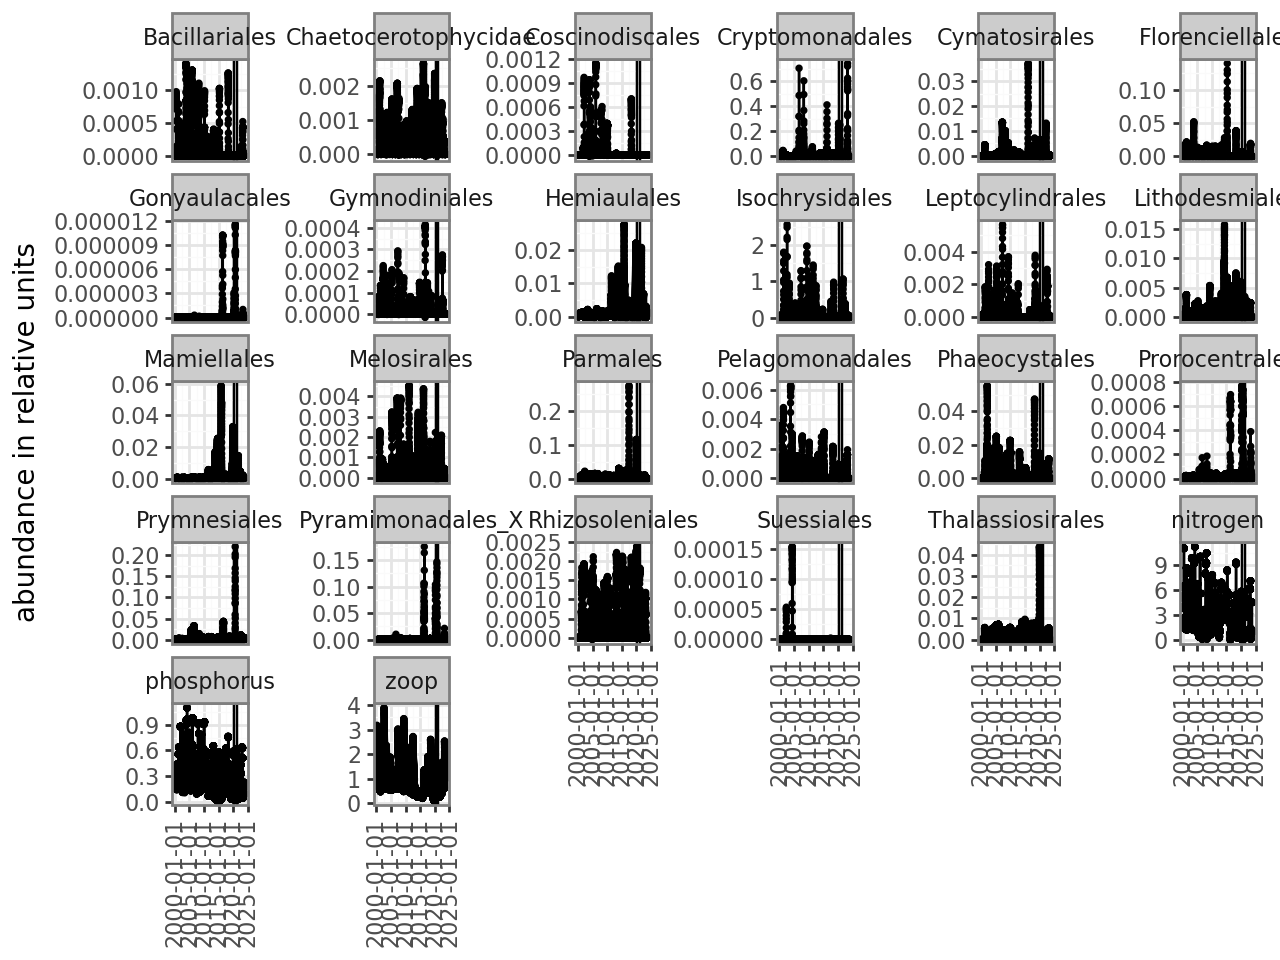

In [104]:
## plot entire timeseries
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42

zoom_in=(plotnine.ggplot(all_sol.loc[all_sol["index"]>50,:]) + 
    plotnine.geom_point(plotnine.aes(x="DateTime",y="abund"),size=0.5)+ 
    plotnine.geom_line(plotnine.aes(x="DateTime",y="abund",group="taxon")) + 
    #plotnine.facet_wrap("taxon",scales="free_y",ncol=1)+
    plotnine.theme_bw(base_size=10)+plotnine.ylab("abundance in relative units") + 
    plotnine.xlab("") +
    plotnine.theme(axis_text_x=plotnine.element_text(rotation=90, hjust=0.5)) +
    plotnine.facet_wrap("taxon",scales="free_y") +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2020-04-01", 
                                                                  "%Y-%m-%d"))) +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2021-04-01", 
                                                                  "%Y-%m-%d"))))
zoom_in

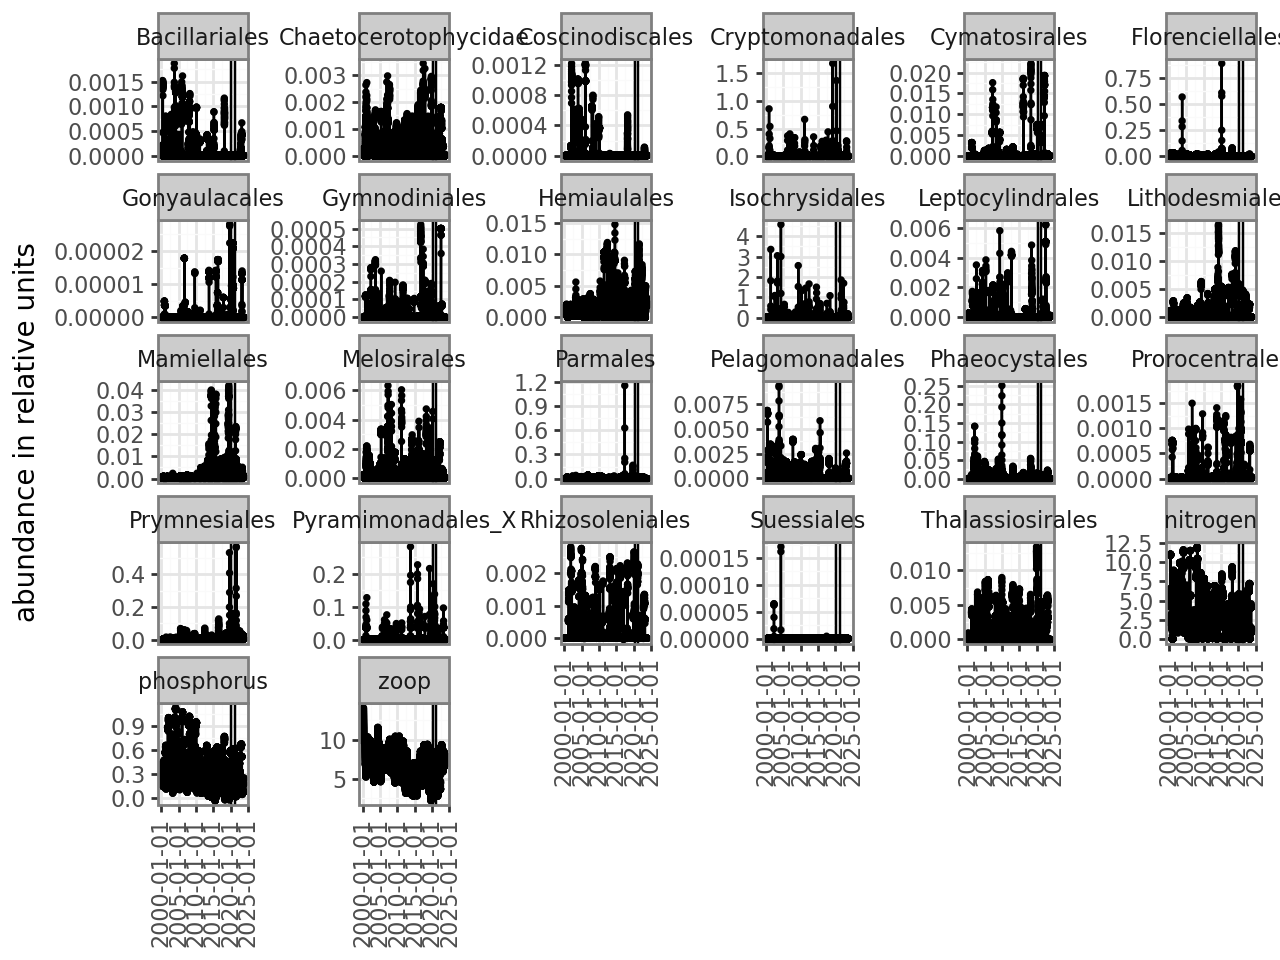

In [98]:
## plot entire timeseries
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42

zoom_in=(plotnine.ggplot(all_sol.loc[all_sol["index"]>50,:]) + 
    plotnine.geom_point(plotnine.aes(x="DateTime",y="abund"),size=0.5)+ 
    plotnine.geom_line(plotnine.aes(x="DateTime",y="abund",group="taxon")) + 
    #plotnine.facet_wrap("taxon",scales="free_y",ncol=1)+
    plotnine.theme_bw(base_size=10)+plotnine.ylab("abundance in relative units") + 
    plotnine.xlab("") +
    plotnine.theme(axis_text_x=plotnine.element_text(rotation=90, hjust=0.5)) +
    plotnine.facet_wrap("taxon",scales="free_y") +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2020-04-01", 
                                                                  "%Y-%m-%d"))) +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2021-04-01", 
                                                                  "%Y-%m-%d"))))
zoom_in

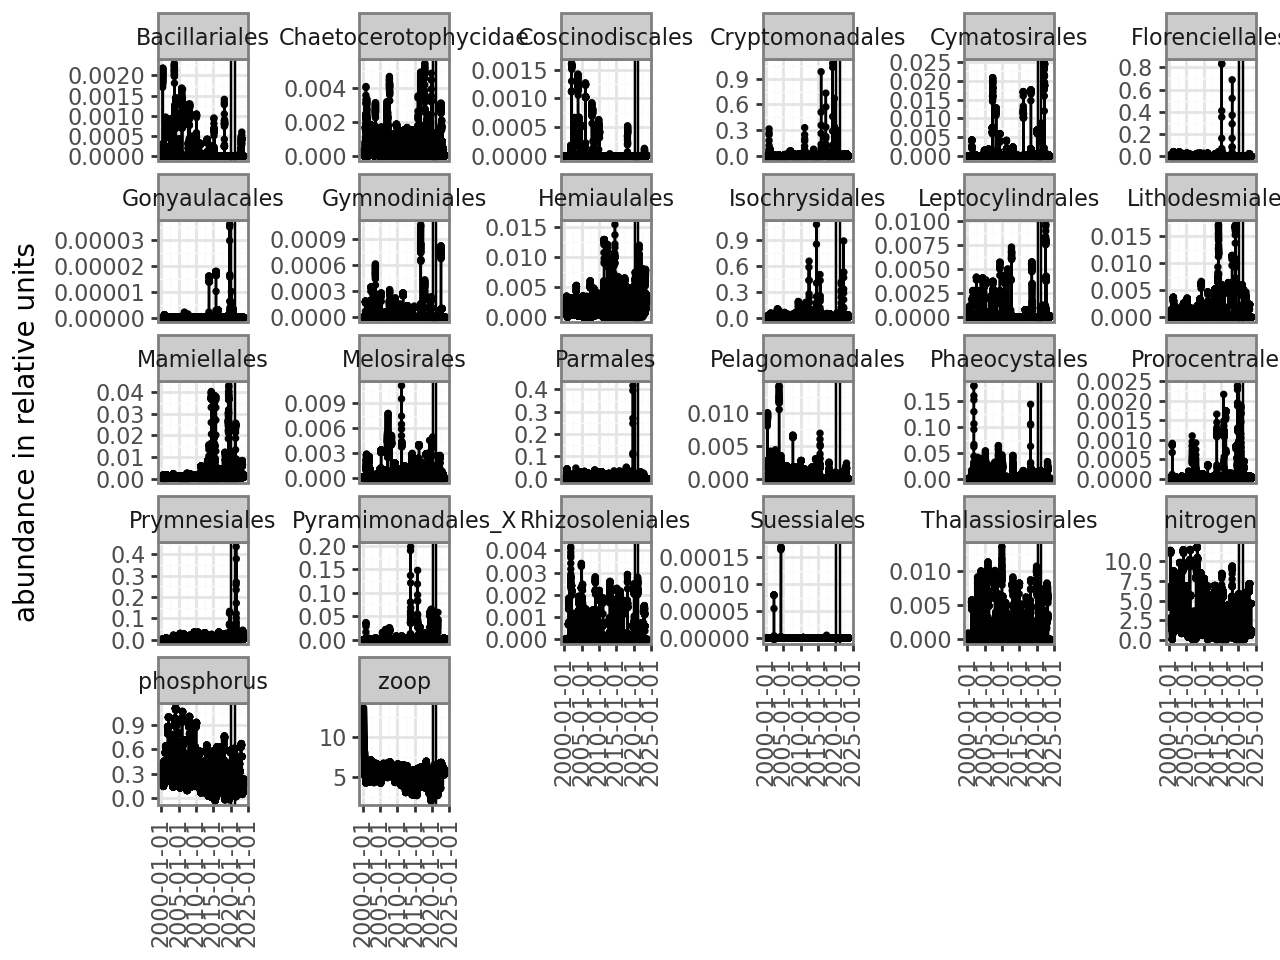

In [63]:
## plot entire timeseries
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42

zoom_in=(plotnine.ggplot(all_sol.loc[all_sol["index"]>50,:]) + 
    plotnine.geom_point(plotnine.aes(x="DateTime",y="abund"),size=0.5)+ 
    plotnine.geom_line(plotnine.aes(x="DateTime",y="abund",group="taxon")) + 
    #plotnine.facet_wrap("taxon",scales="free_y",ncol=1)+
    plotnine.theme_bw(base_size=10)+plotnine.ylab("abundance in relative units") + 
    plotnine.xlab("") +
    plotnine.theme(axis_text_x=plotnine.element_text(rotation=90, hjust=0.5)) +
    plotnine.facet_wrap("taxon",scales="free_y") +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2020-04-01", 
                                                                  "%Y-%m-%d"))) +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2021-04-01", 
                                                                  "%Y-%m-%d"))))
zoom_in

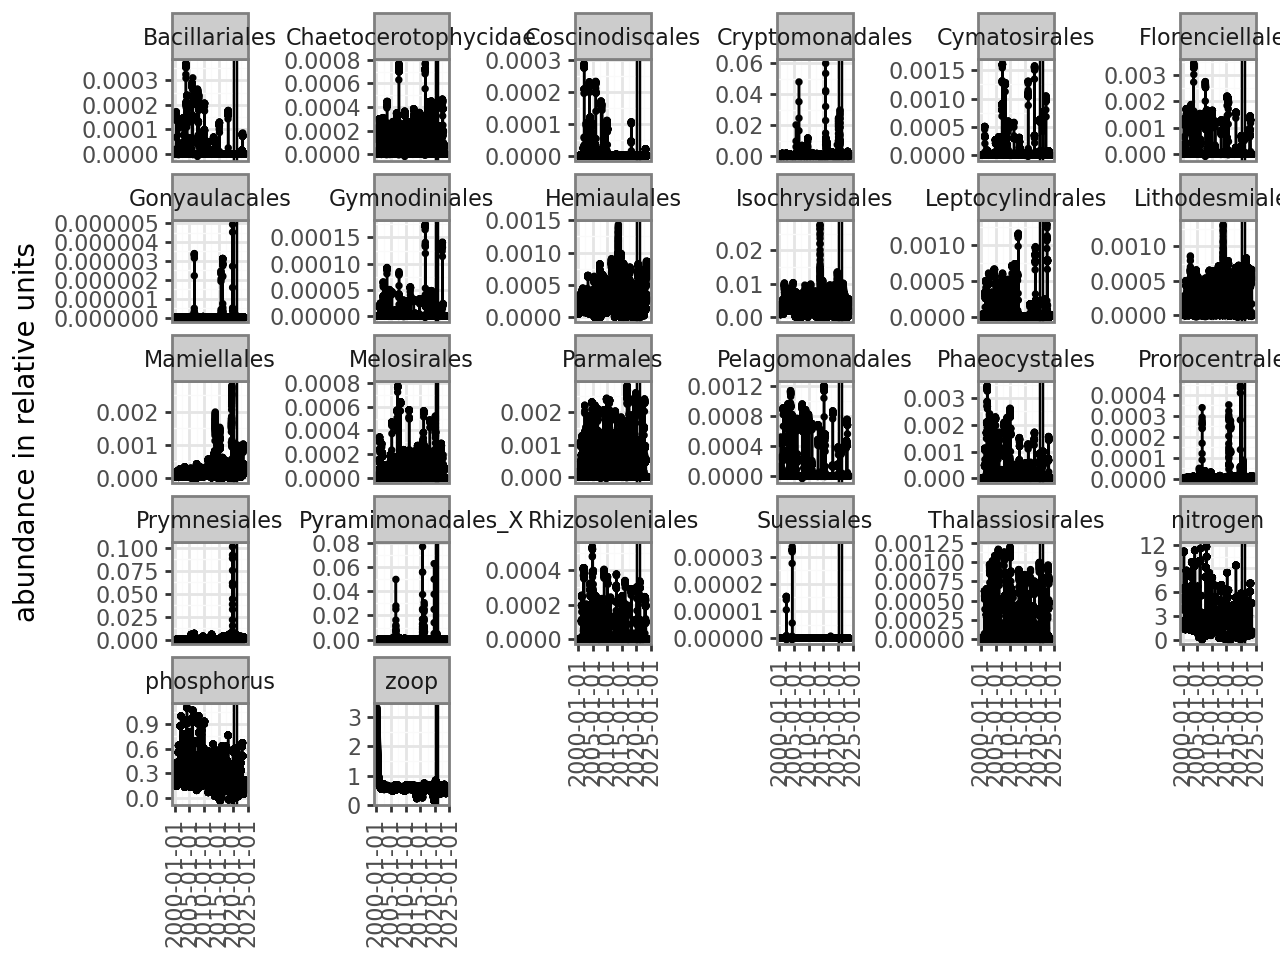

In [150]:
## plot entire timeseries
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42

zoom_in=(plotnine.ggplot(all_sol.loc[all_sol["index"]>50,:]) + 
    plotnine.geom_point(plotnine.aes(x="DateTime",y="abund"),size=0.5)+ 
    plotnine.geom_line(plotnine.aes(x="DateTime",y="abund",group="taxon")) + 
    #plotnine.facet_wrap("taxon",scales="free_y",ncol=1)+
    plotnine.theme_bw(base_size=10)+plotnine.ylab("abundance in relative units") + 
    plotnine.xlab("") +
    plotnine.theme(axis_text_x=plotnine.element_text(rotation=90, hjust=0.5)) +
    plotnine.facet_wrap("taxon",scales="free_y") +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2020-04-01", 
                                                                  "%Y-%m-%d"))) +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2021-04-01", 
                                                                  "%Y-%m-%d"))))
zoom_in

/tmp/ipykernel_3813625/2351203116.py:13: FutureWarning: Logical ops (and, or, xor) between Pandas objects and dtype-less sequences (e.g. list, tuple) are deprecated and will raise in a future version. Wrap the object in a Series, Index, or np.array before operating instead.


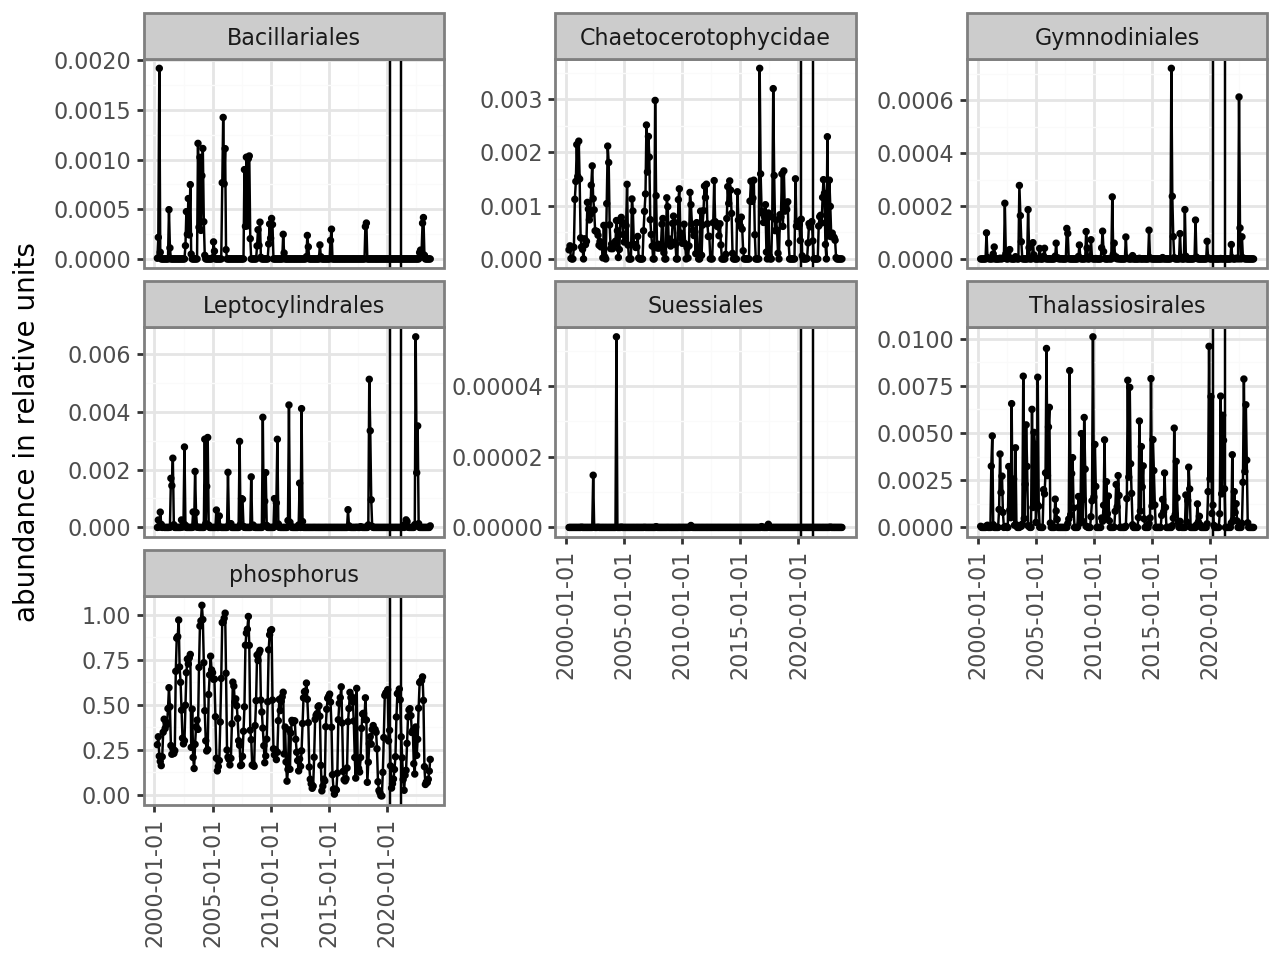

In [64]:
all_sol["month"] = [curr.month for curr in all_sol.DateTime]
all_sol["year"] = [curr.year for curr in all_sol.DateTime]
all_sol_summary = all_sol.groupby(["month","year","taxon"])[["abund","index"]].\
    mean().reset_index()
all_sol_summary["DateTime"] = [datetime(year, month, 1) for \
                               year,month in zip(all_sol_summary.year,
                                                 all_sol_summary.month)]

## plot entire timeseries
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42

zoom_in=(plotnine.ggplot(all_sol_summary.loc[(all_sol_summary["index"]>50)&\
                         ([curr in ['Leptocylindrales',
                                     'Suessiales',
                                     'Bacillariales',
                                     'Gymnodiniales',
                                     'Chaetocerotophycidae',
                                     'Thalassiosirales',
                                     'Phaeocystales'
                                    "nitrogen","phosphorus"] for curr in all_sol_summary.taxon]),:]) + 
    plotnine.geom_point(plotnine.aes(x="DateTime",y="abund"),size=0.5)+ 
    plotnine.geom_line(plotnine.aes(x="DateTime",y="abund",group="taxon")) + 
    #plotnine.facet_wrap("taxon",scales="free_y",ncol=1)+
    plotnine.theme_bw(base_size=10)+plotnine.ylab("abundance in relative units") + 
    plotnine.xlab("") +
    plotnine.theme(axis_text_x=plotnine.element_text(rotation=90, hjust=0.5)) +
    plotnine.facet_wrap("taxon",scales="free_y") +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2020-04-01", 
                                                                  "%Y-%m-%d"))) +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2021-04-01", 
                                                                  "%Y-%m-%d"))))
zoom_in

/tmp/ipykernel_3813625/2459505683.py:13: FutureWarning: Logical ops (and, or, xor) between Pandas objects and dtype-less sequences (e.g. list, tuple) are deprecated and will raise in a future version. Wrap the object in a Series, Index, or np.array before operating instead.


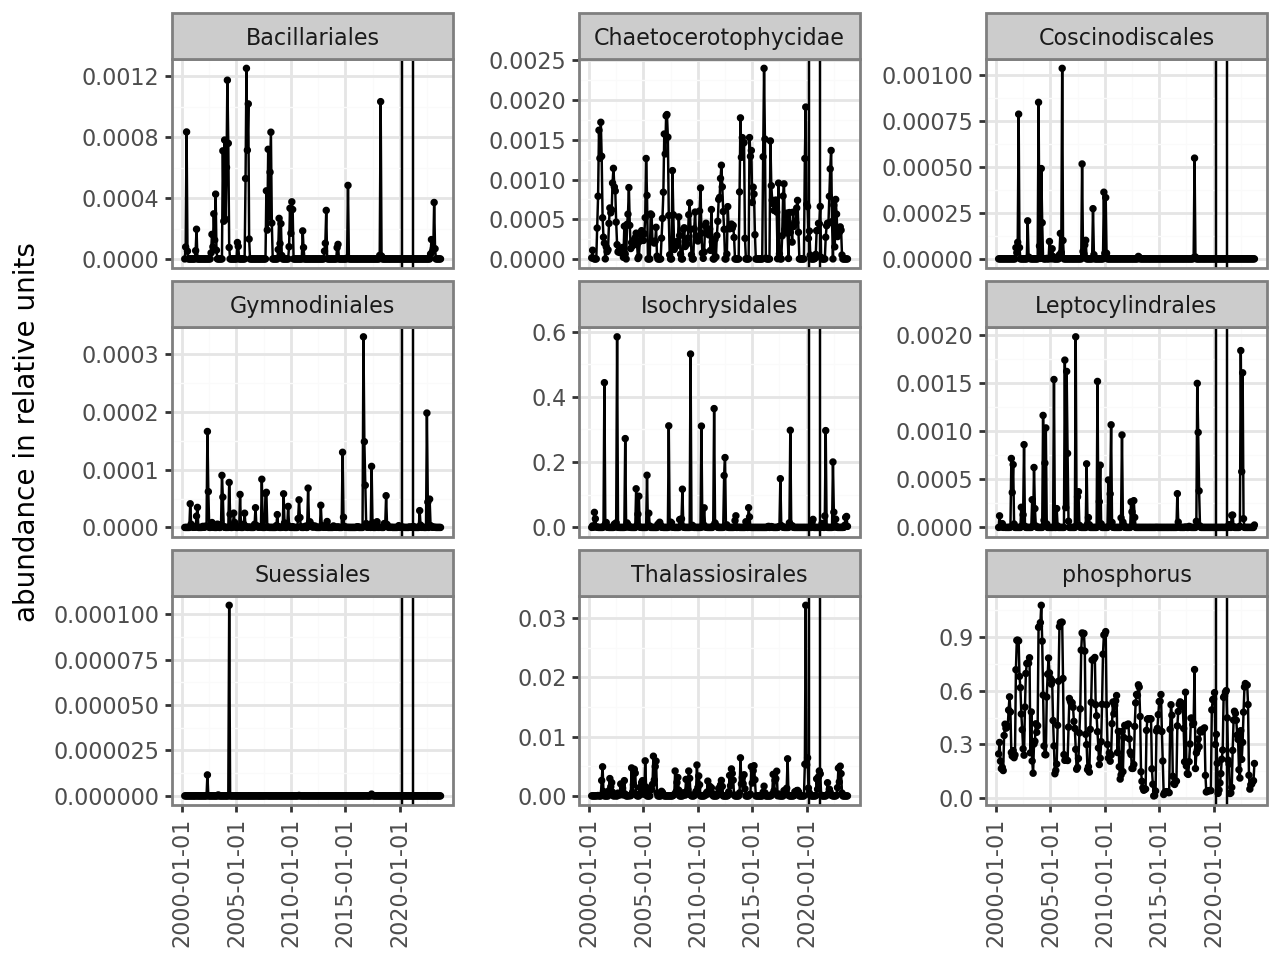

In [106]:
all_sol["month"] = [curr.month for curr in all_sol.DateTime]
all_sol["year"] = [curr.year for curr in all_sol.DateTime]
all_sol_summary = all_sol.groupby(["month","year","taxon"])[["abund","index"]].\
    mean().reset_index()
all_sol_summary["DateTime"] = [datetime(year, month, 1) for \
                               year,month in zip(all_sol_summary.year,
                                                 all_sol_summary.month)]

## plot entire timeseries
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42

zoom_in=(plotnine.ggplot(all_sol_summary.loc[(all_sol_summary["index"]>50)&\
                         ([curr in ['Leptocylindrales',
                                     'Suessiales',
                                     'Isochrysidales',
                                     'Bacillariales',
                                     'Coscinodiscales',
                                     'Gymnodiniales',
                                     'Chaetocerotophycidae',
                                     'Thalassiosirales',
                                     'Phaeocystales'
                                    "nitrogen","phosphorus"] for curr in all_sol_summary.taxon]),:]) + 
    plotnine.geom_point(plotnine.aes(x="DateTime",y="abund"),size=0.5)+ 
    plotnine.geom_line(plotnine.aes(x="DateTime",y="abund",group="taxon")) + 
    #plotnine.facet_wrap("taxon",scales="free_y",ncol=1)+
    plotnine.theme_bw(base_size=10)+plotnine.ylab("abundance in relative units") + 
    plotnine.xlab("") +
    plotnine.theme(axis_text_x=plotnine.element_text(rotation=90, hjust=0.5)) +
    plotnine.facet_wrap("taxon",scales="free_y") +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2020-04-01", 
                                                                  "%Y-%m-%d"))) +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2021-04-01", 
                                                                  "%Y-%m-%d"))))
zoom_in

/tmp/ipykernel_3813625/3237849384.py:13: FutureWarning: Logical ops (and, or, xor) between Pandas objects and dtype-less sequences (e.g. list, tuple) are deprecated and will raise in a future version. Wrap the object in a Series, Index, or np.array before operating instead.


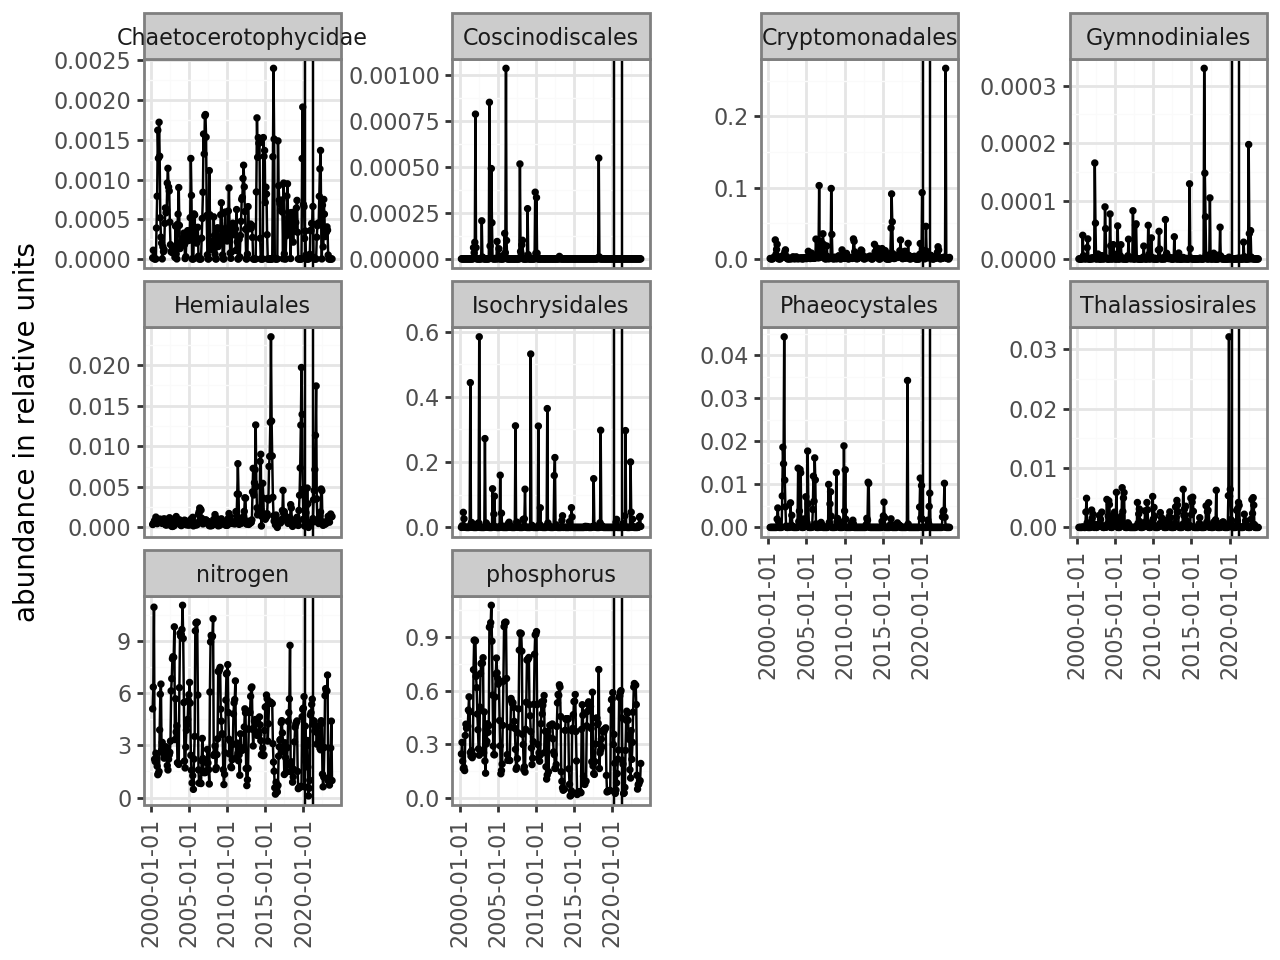

In [110]:
all_sol["month"] = [curr.month for curr in all_sol.DateTime]
all_sol["year"] = [curr.year for curr in all_sol.DateTime]
all_sol_summary = all_sol.groupby(["month","year","taxon"])[["abund","index"]].\
    mean().reset_index()
all_sol_summary["DateTime"] = [datetime(year, month, 1) for \
                               year,month in zip(all_sol_summary.year,
                                                 all_sol_summary.month)]

## plot entire timeseries
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42

zoom_in=(plotnine.ggplot(all_sol_summary.loc[(all_sol_summary["index"]>50)&\
                         ([curr in ["Phaeocystales","Thalassiosirales",
                                    "Isochrysidales","Coscinodiscales",
                                    "Chaetocerotophycidae",
                                    "Gymnodiniales",
                                    "Cryptomonadales","Hemiaulales",
                                    "nitrogen","phosphorus"] for curr in all_sol_summary.taxon]),:]) + 
    plotnine.geom_point(plotnine.aes(x="DateTime",y="abund"),size=0.5)+ 
    plotnine.geom_line(plotnine.aes(x="DateTime",y="abund",group="taxon")) + 
    #plotnine.facet_wrap("taxon",scales="free_y",ncol=1)+
    plotnine.theme_bw(base_size=10)+plotnine.ylab("abundance in relative units") + 
    plotnine.xlab("") +
    plotnine.theme(axis_text_x=plotnine.element_text(rotation=90, hjust=0.5)) +
    plotnine.facet_wrap("taxon",scales="free_y") +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2020-04-01", 
                                                                  "%Y-%m-%d"))) +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2021-04-01", 
                                                                  "%Y-%m-%d"))))
zoom_in

/tmp/ipykernel_3813625/4055282229.py:12: FutureWarning: Logical ops (and, or, xor) between Pandas objects and dtype-less sequences (e.g. list, tuple) are deprecated and will raise in a future version. Wrap the object in a Series, Index, or np.array before operating instead.


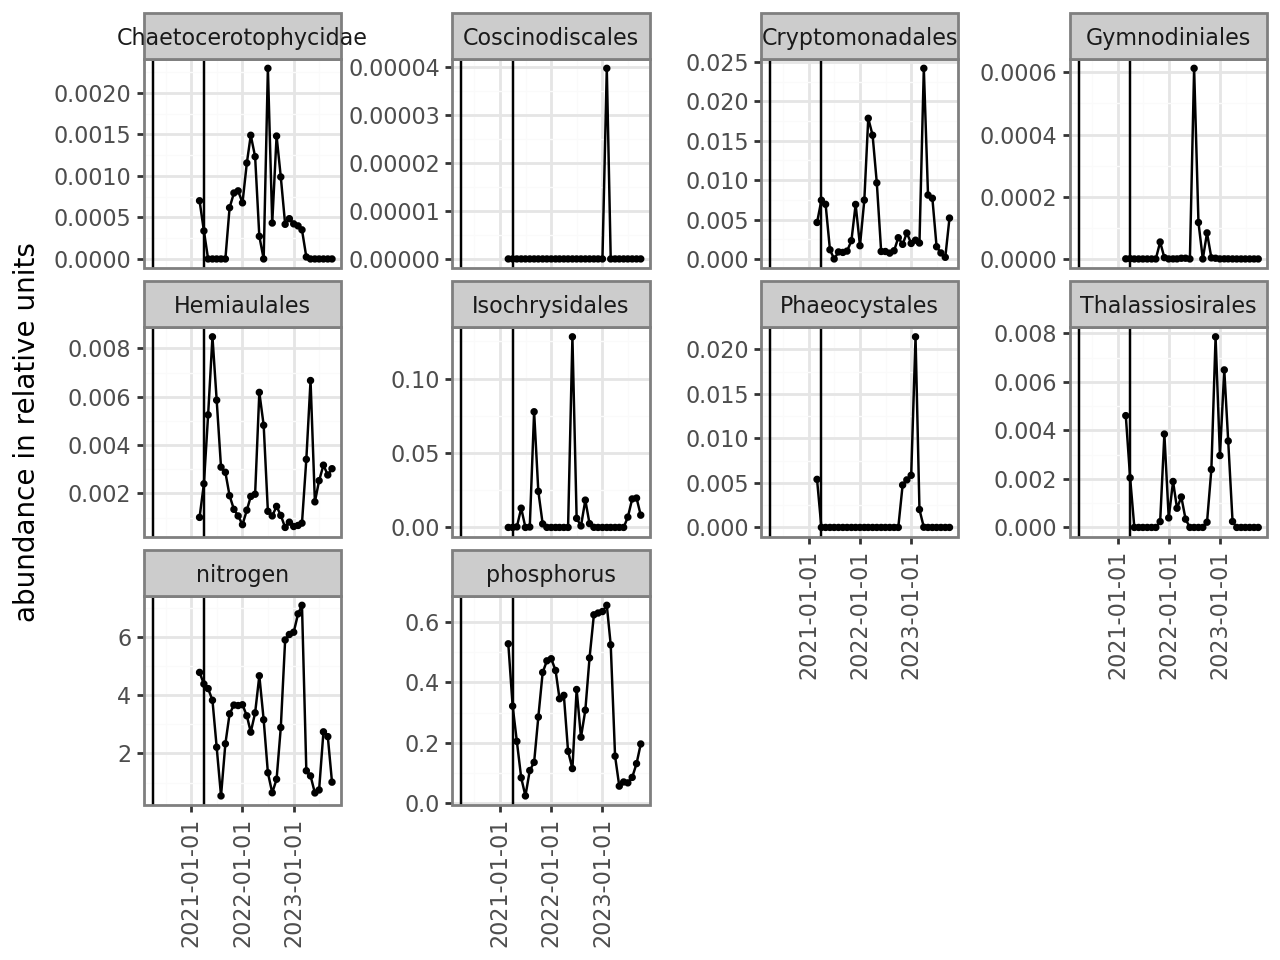

In [67]:
all_sol["month"] = [curr.month for curr in all_sol.DateTime]
all_sol["year"] = [curr.year for curr in all_sol.DateTime]
all_sol_summary = all_sol.groupby(["month","year","taxon"])[["abund","index"]].\
    mean().reset_index()
all_sol_summary["DateTime"] = [datetime(year, month, 1) for \
                               year,month in zip(all_sol_summary.year,
                                                 all_sol_summary.month)]

## plot entire timeseries
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
zoom_in=(plotnine.ggplot(all_sol_summary.loc[(all_sol_summary["index"]>50)&\
                                             (all_sol_summary.DateTime>time_vect[len(time_vect)-1]-timedelta(days = 1000))&\
                         ([curr in ["Phaeocystales","Thalassiosirales",
                                    "Isochrysidales","Coscinodiscales",
                                    "Chaetocerotophycidae",
                                    "Gymnodiniales",
                                    "Cryptomonadales","Hemiaulales",
                                    "nitrogen","phosphorus"] for curr in all_sol_summary.taxon]),:]) + 
    plotnine.geom_point(plotnine.aes(x="DateTime",y="abund"),size=0.5)+ 
    plotnine.geom_line(plotnine.aes(x="DateTime",y="abund",group="taxon")) + 
    #plotnine.facet_wrap("taxon",scales="free_y",ncol=1)+
    plotnine.theme_bw(base_size=10)+plotnine.ylab("abundance in relative units") + 
    plotnine.xlab("") +
    plotnine.theme(axis_text_x=plotnine.element_text(rotation=90, hjust=0.5)) +
    plotnine.facet_wrap("taxon",scales="free_y") +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2020-04-01", 
                                                                  "%Y-%m-%d"))) +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2021-04-01", 
                                                                  "%Y-%m-%d"))))
zoom_in

/tmp/ipykernel_3813625/3299808422.py:12: FutureWarning: Logical ops (and, or, xor) between Pandas objects and dtype-less sequences (e.g. list, tuple) are deprecated and will raise in a future version. Wrap the object in a Series, Index, or np.array before operating instead.


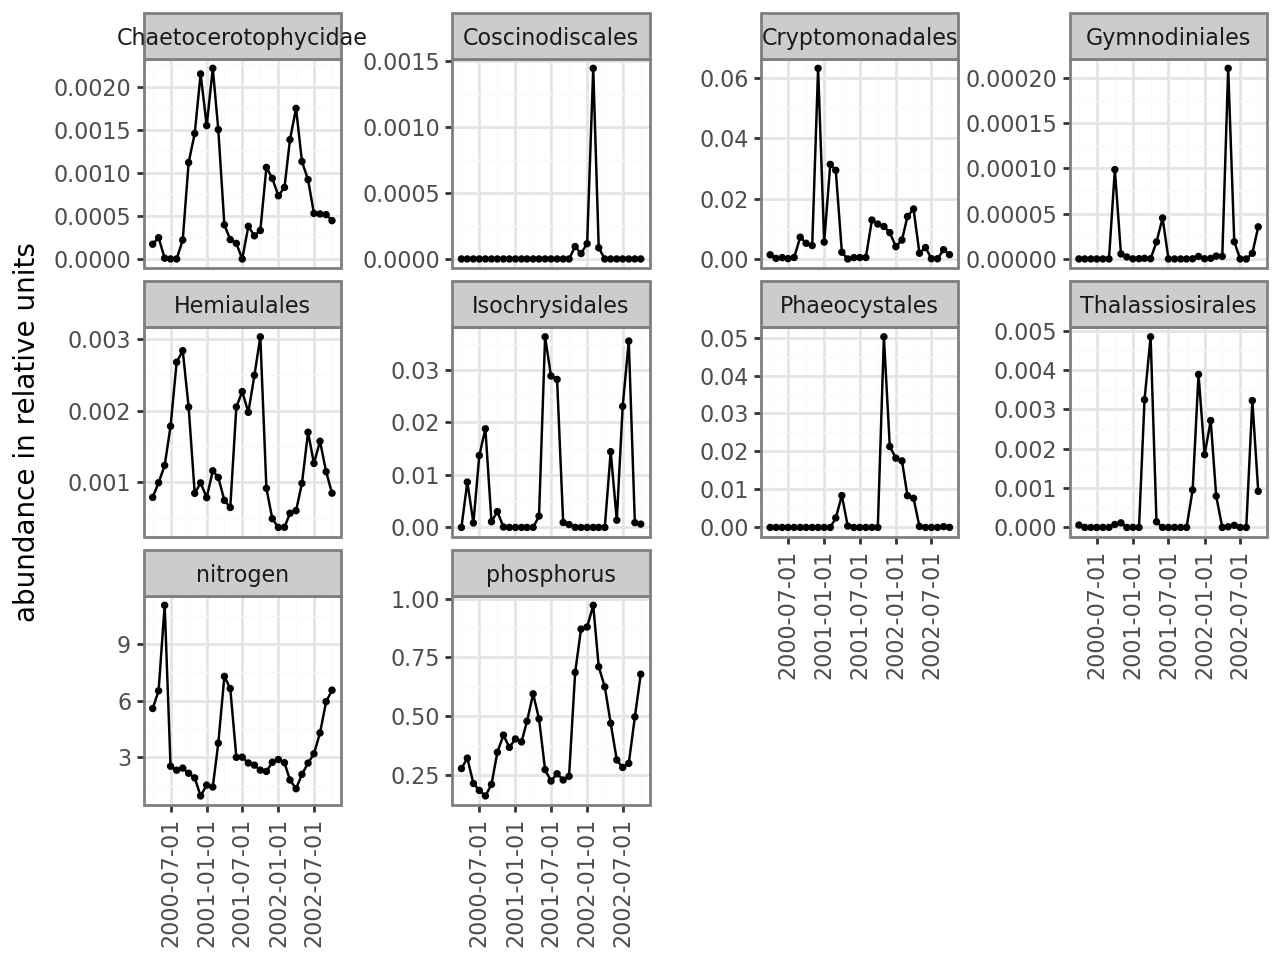

In [69]:
all_sol["month"] = [curr.month for curr in all_sol.DateTime]
all_sol["year"] = [curr.year for curr in all_sol.DateTime]
all_sol_summary = all_sol.groupby(["month","year","taxon"])[["abund","index"]].\
    mean().reset_index()
all_sol_summary["DateTime"] = [datetime(year, month, 1) for \
                               year,month in zip(all_sol_summary.year,
                                                 all_sol_summary.month)]

## plot entire timeseries
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
zoom_in=(plotnine.ggplot(all_sol_summary.loc[(all_sol_summary["index"]>50)&\
                                             (all_sol_summary.DateTime<time_vect[0]+timedelta(days = 1000))&\
                         ([curr in ["Phaeocystales","Thalassiosirales",
                                    "Isochrysidales","Coscinodiscales",
                                    "Chaetocerotophycidae",
                                    "Gymnodiniales",
                                    "Cryptomonadales","Hemiaulales",
                                    "nitrogen","phosphorus"] for curr in all_sol_summary.taxon]),:]) + 
    plotnine.geom_point(plotnine.aes(x="DateTime",y="abund"),size=0.5)+ 
    plotnine.geom_line(plotnine.aes(x="DateTime",y="abund",group="taxon")) + 
    #plotnine.facet_wrap("taxon",scales="free_y",ncol=1)+
    plotnine.theme_bw(base_size=10)+plotnine.ylab("abundance in relative units") + 
    plotnine.xlab("") +
    plotnine.theme(axis_text_x=plotnine.element_text(rotation=90, hjust=0.5)) +
    plotnine.facet_wrap("taxon",scales="free_y"))
zoom_in

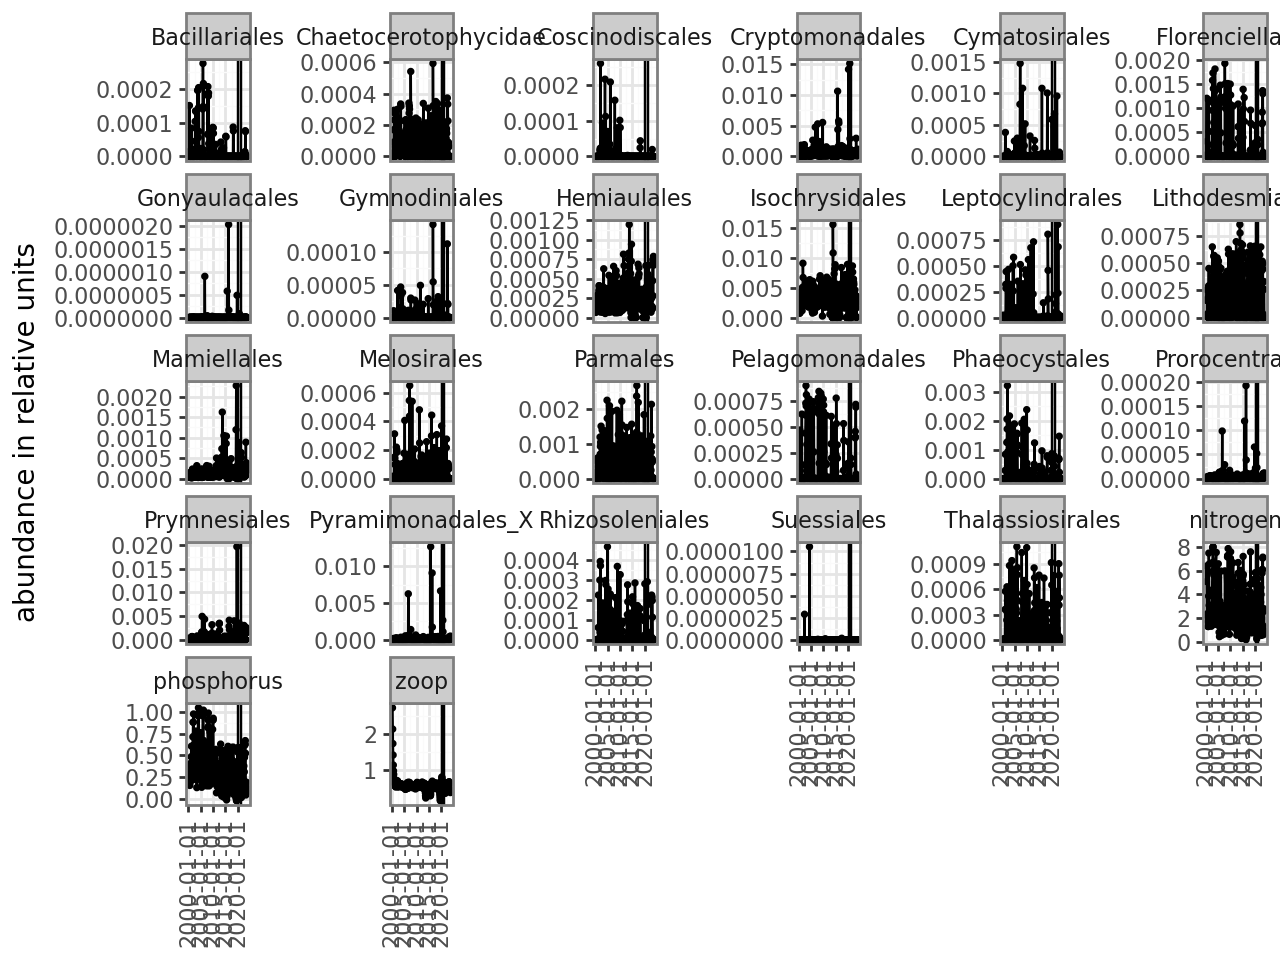

In [87]:
all_sol["month"] = [curr.month for curr in all_sol.DateTime]
all_sol["year"] = [curr.year for curr in all_sol.DateTime]
all_sol_summary = all_sol.groupby(["month","year","taxon"])[["abund","index"]].\
    mean().reset_index()
all_sol_summary = all_sol_summary.loc[all_sol_summary.abund<8]
all_sol_summary["DateTime"] = [datetime(year, month, 1) for \
                               year,month in zip(all_sol_summary.year,
                                                 all_sol_summary.month)]

## plot entire timeseries
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42

zoom_in=(plotnine.ggplot(all_sol_summary.loc[(all_sol_summary["index"]>50),:]) + 
    plotnine.geom_point(plotnine.aes(x="DateTime",y="abund"),size=0.5)+ 
    plotnine.geom_line(plotnine.aes(x="DateTime",y="abund",group="taxon")) + 
    #plotnine.facet_wrap("taxon",scales="free_y",ncol=1)+
    plotnine.theme_bw(base_size=10)+plotnine.ylab("abundance in relative units") + 
    plotnine.xlab("") +
    plotnine.theme(axis_text_x=plotnine.element_text(rotation=90, hjust=0.5)) +
    plotnine.facet_wrap("taxon",scales="free_y") +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2020-04-01", 
                                                                  "%Y-%m-%d"))) +  
    plotnine.geom_vline(plotnine.aes(xintercept=datetime.strptime("2021-04-01", 
                                                                  "%Y-%m-%d"))))
zoom_in

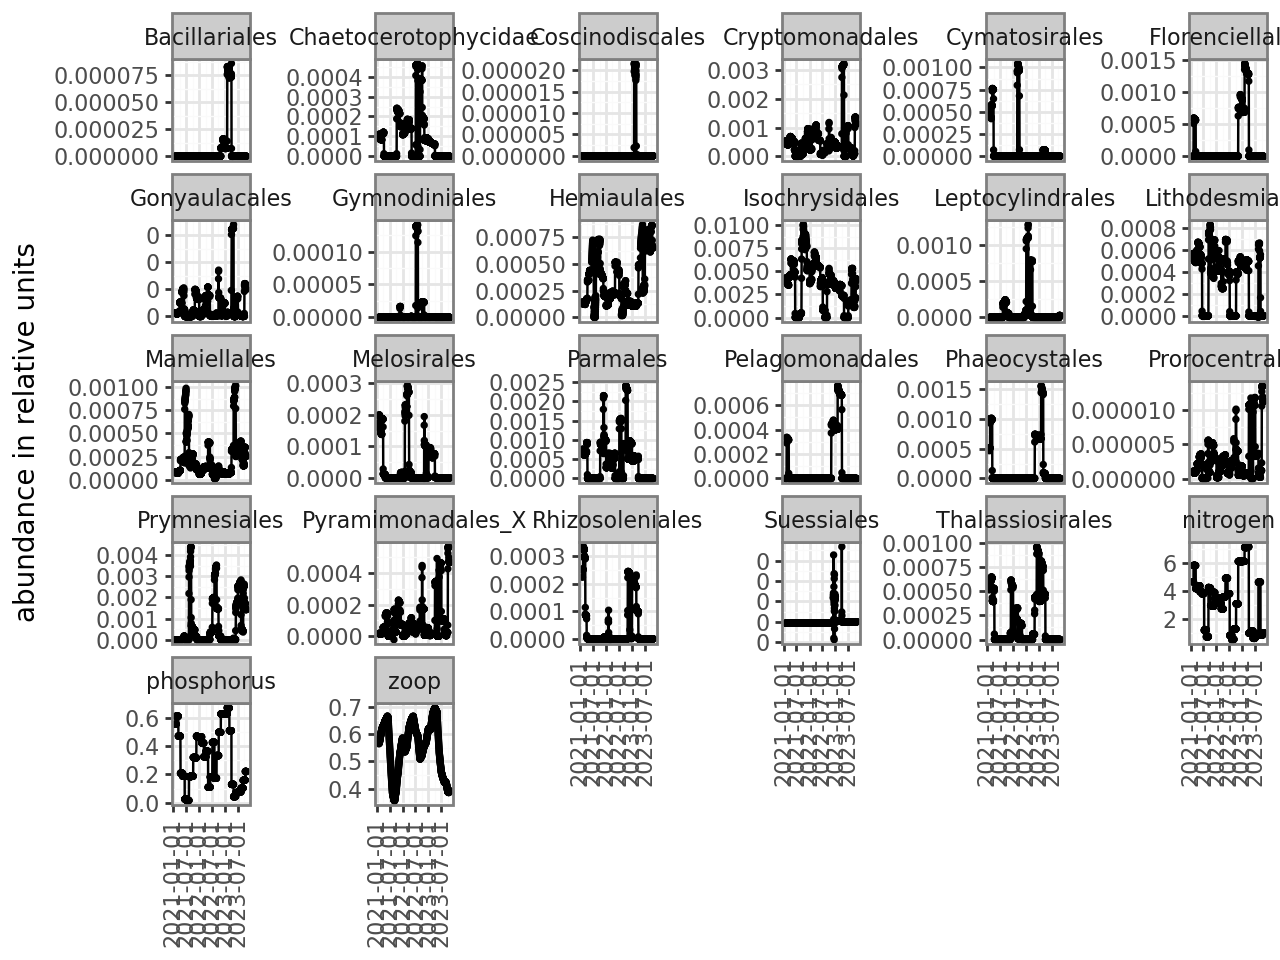

In [90]:
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42

zoom_in=(plotnine.ggplot(all_sol.loc[all_sol.DateTime>time_vect[len(time_vect)-1]-timedelta(days = 1000),:]) + 
    plotnine.geom_point(plotnine.aes(x="DateTime",y="abund"),size=0.5)+ 
    plotnine.geom_line(plotnine.aes(x="DateTime",y="abund",group="taxon")) + 
    #plotnine.facet_wrap("taxon",scales="free_y",ncol=1)+
    plotnine.theme_bw(base_size=10)+plotnine.ylab("abundance in relative units") + 
    plotnine.xlab("") +
    plotnine.theme(axis_text_x=plotnine.element_text(rotation=90, hjust=0.5)) +
    plotnine.facet_wrap("taxon",scales="free_y"))
zoom_in